# 성장 추이 분석 노트 — 모두몰

모두몰 주문 데이터로 **시간 흐름(추이)** 과 **순위** 를 묻는 질문 5개를 만들고, CTE와 윈도우 함수로 답한다.

## 분석 기준

- 데이터: `customers`, `products`, `orders`, `order_items` (2023-09 ~ 2024-02)
- 주문 매출: `orders.amount` 가 있는 주문만 사용한다. 금액이 없는 Cancelled 주문은 제외한다.
- 상품 매출: `order_items` 의 `quantity × unit_price` 로 계산한다.
- 실행 환경: DuckDB (Python 패키지 `duckdb`)

## 질문 목록과 사용한 기법

| # | 질문 | CTE | 사용한 윈도우 함수 |
|---|---|---|---|
| Q1 | 월 매출과 누적 매출은 어떻게 쌓였나? | ✅ | `SUM() OVER (ORDER BY)` 누적, `SUM() OVER ()` 전체 합 |
| Q2 | 전월 대비 매출은 얼마나 늘고 줄었나? | ✅ 2단계 | `LAG`, `RANK`, `NULLIF` |
| Q3 | 매출 1위 카테고리와 카테고리별 베스트셀러는? | ✅ 2단계 | `ROW_NUMBER` / `DENSE_RANK` + `PARTITION BY`, `SUM() OVER (PARTITION BY)` |
| Q4 | 매출은 상위 고객에게 얼마나 몰려 있나? | ✅ 2단계 | `DENSE_RANK`, `SUM() OVER (ORDER BY)` 누적 비중 |
| Q5 | 고객은 얼마 만에 다시 구매하나? | ✅ | `LAG` + `PARTITION BY`, `ROW_NUMBER` |

과제 조건(CTE 2개 이상, 순위 함수 1회 이상, LAG/LEAD 1회 이상, 누적 SUM 1회 이상)을 모두 충족한다.

## 0. 준비 — 데이터 만들기

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()

def q(sql):
    """SQL을 실행하고 결과를 pandas DataFrame으로 돌려준다."""
    return con.sql(sql).df()

In [2]:
con.execute("""
ATTACH IF NOT EXISTS ':memory:' AS project_name;
CREATE SCHEMA IF NOT EXISTS project_name.dataset_name;

CREATE OR REPLACE TABLE project_name.dataset_name.customers (
  customer_id STRING, name STRING, country STRING, signup_date DATE, grade STRING
);
INSERT INTO project_name.dataset_name.customers VALUES
  ('C001', '김민준', 'Korea', '2023-01-05', 'Gold'),
  ('C002', '이서연', 'Korea', '2023-02-11', 'Silver'),
  ('C003', '박도윤', 'Japan', '2023-02-20', 'Bronze'),
  ('C004', '최지우', 'USA', '2023-03-03', 'Gold'),
  ('C005', '정하준', 'Korea', '2023-03-15', 'Silver'),
  ('C006', '강서윤', 'Korea', '2023-04-01', 'Bronze'),
  ('C007', '조은우', 'Japan', '2023-04-18', 'Silver'),
  ('C008', '윤지호', 'USA', '2023-05-09', 'Gold'),
  ('C009', '임하은', 'Korea', '2023-05-22', 'Bronze'),
  ('C010', '한예준', 'Korea', '2023-06-02', 'Silver'),
  ('C011', '오시우', NULL, '2023-06-19', 'Bronze'),
  ('C012', '신아린', 'Japan', '2023-07-07', 'Silver'),
  ('C013', '권준서', 'Korea', '2023-07-25', 'Gold'),
  ('C014', '황지안', 'USA', '2023-08-10', NULL),
  ('C015', '안수아', 'Korea', '2023-08-28', 'Bronze');

CREATE OR REPLACE TABLE project_name.dataset_name.products (
  product_id STRING, product_name STRING, category STRING, price DECIMAL(12,2)
);
INSERT INTO project_name.dataset_name.products VALUES
  ('P01', '에어러너', 'Running', 89000),
  ('P02', '클래식 스니커즈', 'Sneakers', 65000),
  ('P03', '첼시 부츠', 'Boots', 145000),
  ('P04', '여름 샌들', 'Sandals', 38000),
  ('P05', '트레일 러너', 'Running', 119000),
  ('P06', '캔버스 스니커즈', 'Sneakers', 49000),
  ('P07', '워커 부츠', 'Boots', 175000),
  ('P08', '슬리퍼 샌들', 'Sandals', 25000),
  ('P09', '양말 세트', 'Accessory', 12000),
  ('P10', '운동화 끈', 'Accessory', 5000);

CREATE OR REPLACE TABLE project_name.dataset_name.orders (
  order_id STRING, customer_id STRING, order_date DATE, status STRING, amount DECIMAL(12,2)
);
INSERT INTO project_name.dataset_name.orders VALUES
  ('O0001', 'C001', '2023-09-02', 'Paid', 125000),
  ('O0002', 'C002', '2023-09-05', 'Shipped', 89000),
  ('O0003', 'C001', '2023-09-11', 'Returned', 45000),
  ('O0004', 'C003', '2023-09-15', 'Paid', 230000),
  ('O0005', 'C004', '2023-09-20', 'Cancelled', NULL),
  ('O0006', 'C005', '2023-09-25', 'Shipped', 67000),
  ('O0007', 'C002', '2023-10-01', 'Paid', 158000),
  ('O0008', 'C006', '2023-10-04', 'Placed', 32000),
  ('O0009', 'C007', '2023-10-12', 'Shipped', 410000),
  ('O0010', 'C008', '2023-10-19', 'Paid', 99000),
  ('O0011', 'C001', '2023-10-23', 'Paid', 76000),
  ('O0012', 'C009', '2023-10-28', 'Cancelled', NULL),
  ('O0013', 'C010', '2023-11-02', 'Shipped', 142000),
  ('O0014', 'C004', '2023-11-08', 'Paid', 88000),
  ('O0015', 'C011', '2023-11-13', 'Placed', 53000),
  ('O0016', 'C012', '2023-11-19', 'Shipped', 175000),
  ('O0017', 'C002', '2023-11-24', 'Returned', 61000),
  ('O0018', 'C013', '2023-11-29', 'Paid', 320000),
  ('O0019', 'C005', '2023-12-03', 'Paid', 47000),
  ('O0020', 'C008', '2023-12-09', 'Shipped', 215000),
  ('O0021', 'C014', '2023-12-14', 'Placed', 38000),
  ('O0022', 'C001', '2023-12-20', 'Paid', 134000),
  ('O0023', 'C015', '2023-12-25', 'Shipped', 92000),
  ('O0024', 'C007', '2024-01-03', 'Paid', 268000),
  ('O0025', 'C010', '2024-01-09', 'Cancelled', NULL),
  ('O0026', 'C003', '2024-01-15', 'Paid', 119000),
  ('O0027', 'C013', '2024-01-22', 'Shipped', 405000),
  ('O0028', 'C006', '2024-01-28', 'Paid', 58000),
  ('O0029', 'C004', '2024-02-04', 'Returned', 73000),
  ('O0030', 'C012', '2024-02-11', 'Paid', 187000);

CREATE OR REPLACE TABLE project_name.dataset_name.order_items (
  order_id STRING, product_id STRING, quantity INT64, unit_price DECIMAL(12,2)
);
INSERT INTO project_name.dataset_name.order_items VALUES
  ('O0001', 'P01', 1, 125000), ('O0002', 'P02', 2, 44500), ('O0003', 'P03', 1, 45000),
  ('O0004', 'P04', 2, 115000), ('O0006', 'P05', 1, 67000), ('O0007', 'P06', 2, 79000),
  ('O0008', 'P07', 1, 32000),  ('O0009', 'P08', 2, 205000), ('O0010', 'P09', 1, 99000),
  ('O0011', 'P01', 2, 38000),  ('O0013', 'P02', 1, 142000), ('O0014', 'P03', 2, 44000),
  ('O0015', 'P04', 1, 53000),  ('O0016', 'P05', 2, 87500), ('O0017', 'P06', 1, 61000),
  ('O0018', 'P07', 2, 160000), ('O0019', 'P08', 1, 47000), ('O0020', 'P09', 2, 107500),
  ('O0021', 'P01', 1, 38000),  ('O0022', 'P02', 2, 67000), ('O0023', 'P03', 1, 92000),
  ('O0024', 'P04', 2, 134000), ('O0026', 'P05', 1, 119000), ('O0027', 'P06', 2, 202500),
  ('O0028', 'P07', 1, 58000),  ('O0029', 'P08', 2, 36500), ('O0030', 'P09', 1, 187000);
""")
print("테이블 4개 생성 완료")

테이블 4개 생성 완료


---
## Q1. 월 매출과 누적 매출은 어떻게 쌓였나?

월별 매출을 먼저 CTE로 만들고, `SUM() OVER (ORDER BY month)` 로 첫 달부터 그 달까지의 누적 매출을 구한다.
`SUM() OVER ()` 로 전체 매출을 같은 행에 붙여 누적 비중(%)도 계산한다.

In [3]:
q1 = q("""
WITH monthly AS (                                   -- 1단계: 월별 매출
    SELECT
        DATE_TRUNC('month', order_date)::DATE AS month,
        COUNT(*)    AS orders,
        SUM(amount) AS revenue
    FROM project_name.dataset_name.orders
    WHERE amount IS NOT NULL
    GROUP BY month
)
SELECT
    month,
    orders,
    revenue,
    SUM(revenue) OVER (ORDER BY month) AS cumulative_revenue,           -- 누적 매출
    ROUND(SUM(revenue) OVER (ORDER BY month) * 100.0
          / SUM(revenue) OVER (), 1)   AS cumulative_pct                -- 누적 비중(%)
FROM monthly
ORDER BY month
""")
q1

,month,orders,revenue,cumulative_revenue,cumulative_pct
0,2023-09-01,5,556000.0,556000.0,14.6
1,2023-10-01,5,775000.0,1331000.0,35.0
2,2023-11-01,6,839000.0,2170000.0,57.0
3,2023-12-01,5,526000.0,2696000.0,70.8
4,2024-01-01,4,850000.0,3546000.0,93.2
5,2024-02-01,2,260000.0,3806000.0,100.0


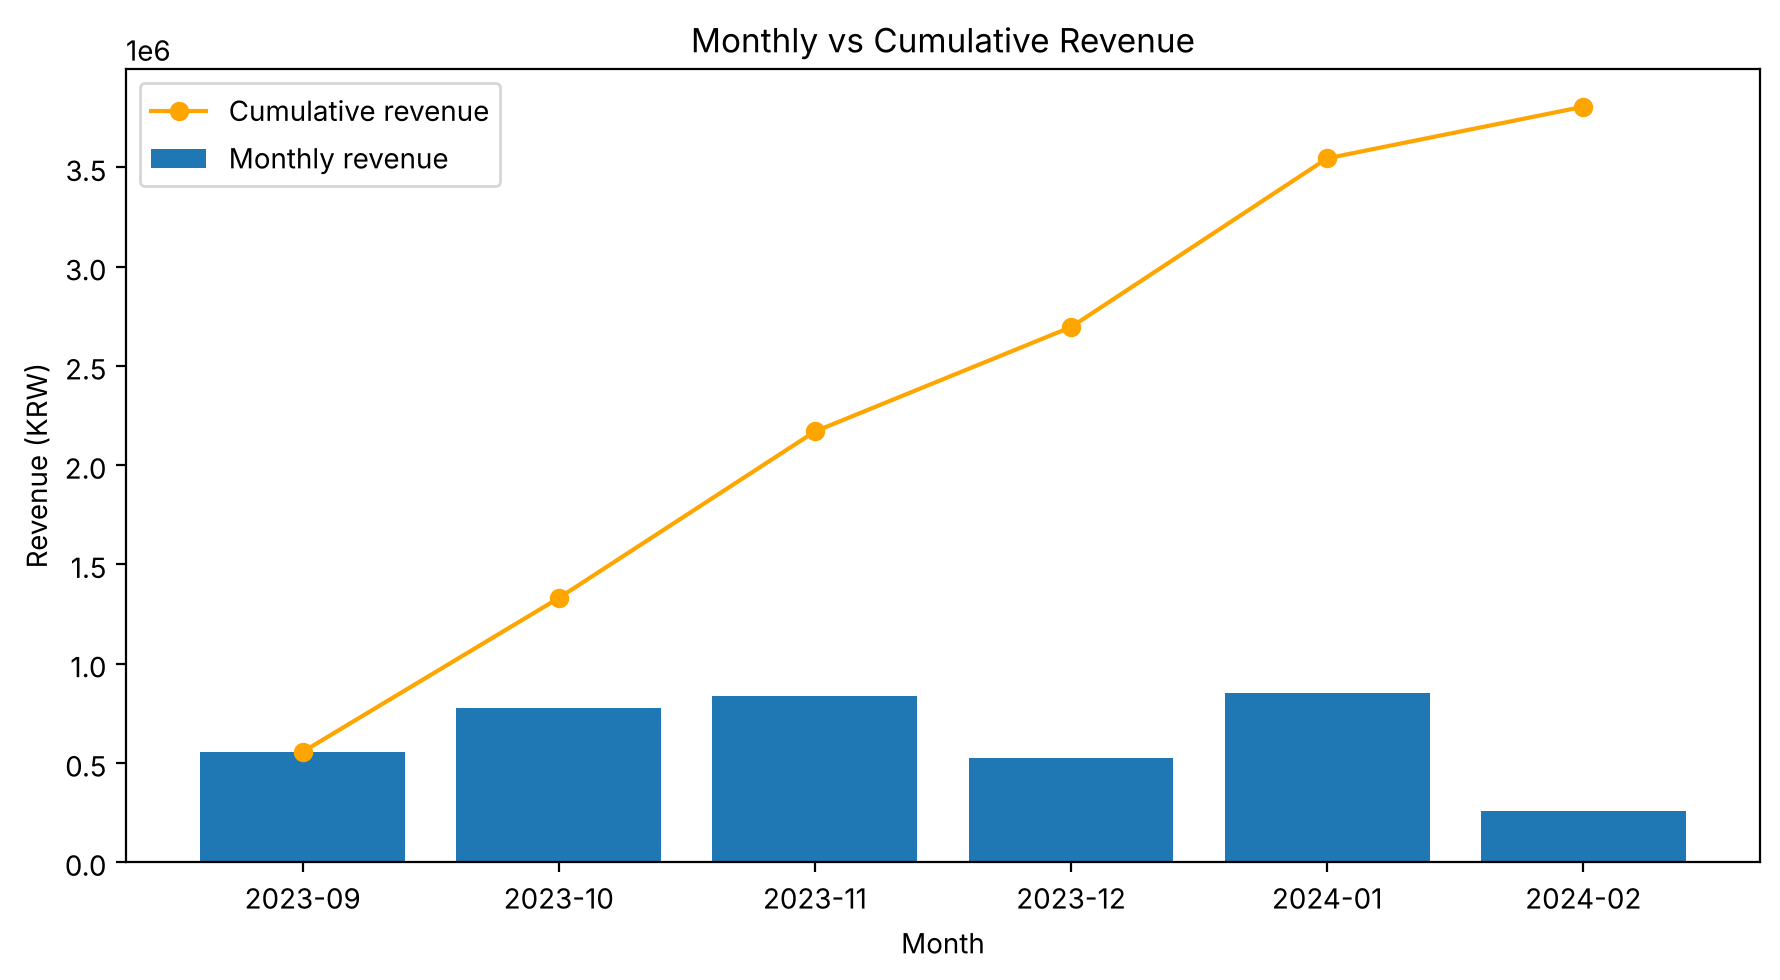

In [4]:
labels = q1["month"].astype(str).str[:7]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(labels, q1["revenue"], label="Monthly revenue")
ax.plot(labels, q1["cumulative_revenue"], marker="o", color="orange", label="Cumulative revenue")
ax.set_title("Monthly vs Cumulative Revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (KRW)")
ax.legend()
plt.tight_layout()
plt.show()

**💡 인사이트:** 6개월 누적 매출은 3,806,000원이며, 1월까지 전체의 93.2%가 쌓였다. 2월은 2건·260,000원뿐인데, 데이터가 2월 11일에서 끝나므로 실제 부진이라기보다 **집계 기간이 짧은 영향**일 가능성이 크다.

---
## Q2. 전월 대비 매출은 얼마나 늘고 줄었나?

1단계 CTE에서 월별 매출을, 2단계 CTE에서 `LAG` 로 전월 매출을 같은 행에 붙인다.
증감률은 `(이번 달 − 전월) / 전월 × 100` 이며, 전월이 0일 때 오류가 나지 않도록 `NULLIF(prev_revenue, 0)` 으로 나눈다.
참고로 `RANK` 로 월 매출 순위도 함께 붙인다.

In [5]:
q2 = q("""
WITH monthly AS (                                   -- 1단계: 월별 매출
    SELECT
        DATE_TRUNC('month', order_date)::DATE AS month,
        SUM(amount) AS revenue
    FROM project_name.dataset_name.orders
    WHERE amount IS NOT NULL
    GROUP BY month
),
with_prev AS (                                      -- 2단계: 전월 매출 붙이기
    SELECT
        month,
        revenue,
        LAG(revenue) OVER (ORDER BY month) AS prev_revenue
    FROM monthly
)
SELECT
    month,
    revenue,
    prev_revenue,
    ROUND((revenue - prev_revenue) * 100.0 / NULLIF(prev_revenue, 0), 2) AS growth_pct,
    RANK() OVER (ORDER BY revenue DESC) AS revenue_rank
FROM with_prev
ORDER BY month
""")
q2

,month,revenue,prev_revenue,growth_pct,revenue_rank
0,2023-09-01,556000.0,NaN,NaN,4
1,2023-10-01,775000.0,556000.0,39.39,3
2,2023-11-01,839000.0,775000.0,8.26,2
3,2023-12-01,526000.0,839000.0,-37.31,5
4,2024-01-01,850000.0,526000.0,61.60,1
5,2024-02-01,260000.0,850000.0,-69.41,6


**💡 인사이트:** 매출은 꾸준히 오르지 않고 **오르고 내리기를 반복한다** (10월 +39.4% → 12월 −37.3% → 1월 +61.6%). 1월 매출 1위는 큰 주문 2건(O0027 405,000원, O0024 268,000원)이 1월 매출의 79%를 차지한 결과로, 이 규모에서는 **큰 주문 몇 건이 월 성과를 좌우한다**.

---
## Q3. 매출 1위 카테고리와 카테고리별 베스트셀러는?

`order_items` 와 `products` 를 JOIN 해 상품별 매출을 만든 뒤,

- `SUM() OVER (PARTITION BY category)` 로 행을 유지한 채 카테고리 매출을 붙이고
- `ROW_NUMBER() OVER (PARTITION BY category ...)` 로 카테고리 안 상품 순위를,
- `DENSE_RANK()` 로 카테고리 간 순위를 매긴다.

In [6]:
q3 = q("""
WITH product_rev AS (                               -- 1단계: 상품별 매출
    SELECT
        p.category,
        p.product_name,
        SUM(oi.quantity)                 AS qty,
        SUM(oi.quantity * oi.unit_price) AS revenue
    FROM project_name.dataset_name.order_items AS oi
    JOIN project_name.dataset_name.products    AS p
        ON oi.product_id = p.product_id
    GROUP BY p.category, p.product_name
),
ranked AS (                                         -- 2단계: 카테고리 합계 + 카테고리 안 순위
    SELECT
        *,
        SUM(revenue) OVER (PARTITION BY category) AS category_revenue,
        ROW_NUMBER() OVER (PARTITION BY category ORDER BY revenue DESC) AS rank_in_category
    FROM product_rev
)
SELECT
    category,
    product_name,
    qty,
    revenue,
    category_revenue,
    ROUND(revenue * 100.0 / category_revenue, 1)       AS share_in_category_pct,
    DENSE_RANK() OVER (ORDER BY category_revenue DESC) AS category_rank,
    rank_in_category
FROM ranked
ORDER BY category_rank, rank_in_category
""")
q3

,category,product_name,qty,revenue,category_revenue,share_in_category_pct,category_rank,rank_in_category
0,Sandals,여름 샌들,5.0,551000.0,1081000.0,51.0,1,1
1,Sandals,슬리퍼 샌들,5.0,530000.0,1081000.0,49.0,1,2
2,Sneakers,캔버스 스니커즈,5.0,624000.0,989000.0,63.1,2,1
3,Sneakers,클래식 스니커즈,5.0,365000.0,989000.0,36.9,2,2
4,Boots,워커 부츠,4.0,410000.0,635000.0,64.6,3,1
5,Boots,첼시 부츠,4.0,225000.0,635000.0,35.4,3,2
6,Running,트레일 러너,4.0,361000.0,600000.0,60.2,4,1
7,Running,에어러너,4.0,239000.0,600000.0,39.8,4,2
8,Accessory,양말 세트,4.0,501000.0,501000.0,100.0,5,1


In [7]:
# 카테고리별 베스트셀러(1위 상품)만 보기
q3[q3["rank_in_category"] == 1][["category_rank", "category", "product_name", "revenue", "share_in_category_pct"]]

,category_rank,category,product_name,revenue,share_in_category_pct
0,1,Sandals,여름 샌들,551000.0,51.0
2,2,Sneakers,캔버스 스니커즈,624000.0,63.1
4,3,Boots,워커 부츠,410000.0,64.6
6,4,Running,트레일 러너,361000.0,60.2
8,5,Accessory,양말 세트,501000.0,100.0


**💡 인사이트:** 매출 1위 카테고리는 Sandals(1,081,000원)이며, 두 상품이 51:49로 고르게 팔린다. 반면 Sneakers·Boots·Running은 1위 상품이 카테고리 매출의 60% 이상을 차지해 **베스트셀러 한 개에 의존**하고, Accessory의 운동화 끈은 판매가 한 건도 없다.

---
## Q4. 매출은 상위 고객에게 얼마나 몰려 있나?

고객별 총구매액을 CTE로 만든 뒤 `DENSE_RANK` 로 순위를 매기고,
구매액 큰 순서로 `SUM() OVER (ORDER BY total_amount DESC)` 누적 합을 구해 **상위 N명이 전체 매출의 몇 %를 차지하는지** 본다.
고객 등급(grade)과 비교하기 위해 `customers` 를 붙인다.

In [8]:
q4 = q("""
WITH customer_total AS (                            -- 1단계: 고객별 총구매액
    SELECT
        customer_id,
        COUNT(*)    AS orders,
        SUM(amount) AS total_amount
    FROM project_name.dataset_name.orders
    WHERE amount IS NOT NULL
    GROUP BY customer_id
),
ranked AS (                                         -- 2단계: 순위 + 누적 구매액
    SELECT
        *,
        DENSE_RANK() OVER (ORDER BY total_amount DESC) AS purchase_rank,
        SUM(total_amount) OVER (ORDER BY total_amount DESC, customer_id) AS cumulative_amount,
        SUM(total_amount) OVER () AS grand_total
    FROM customer_total
)
SELECT
    r.customer_id,
    c.name,
    c.grade,
    r.orders,
    r.total_amount,
    r.purchase_rank,
    ROUND(r.cumulative_amount * 100.0 / r.grand_total, 1) AS cumulative_pct
FROM ranked AS r
LEFT JOIN project_name.dataset_name.customers AS c
    ON r.customer_id = c.customer_id
ORDER BY r.purchase_rank
""")
q4

,customer_id,name,grade,orders,total_amount,purchase_rank,cumulative_pct
0,C013,권준서,Gold,2,725000.0,1,19.0
1,C007,조은우,Silver,2,678000.0,2,36.9
2,C001,김민준,Gold,4,380000.0,3,46.8
3,C012,신아린,Silver,2,362000.0,4,56.4
4,C003,박도윤,Bronze,2,349000.0,5,65.5
5,C008,윤지호,Gold,2,314000.0,6,73.8
6,C002,이서연,Silver,3,308000.0,7,81.9
7,C004,최지우,Gold,2,161000.0,8,86.1
8,C010,한예준,Silver,1,142000.0,9,89.8
9,C005,정하준,Silver,2,114000.0,10,92.8


**💡 인사이트:** 구매 고객 14명 중 **상위 5명(약 36%)이 전체 매출의 65.5%** 를 만든다. 또 Gold 등급인 최지우(C004)는 8위, Bronze인 박도윤(C003)은 5위로, 현재 등급이 실제 구매액과 맞지 않아 **등급 기준 재검토**가 필요해 보인다.

---
## Q5. 고객은 얼마 만에 다시 구매하나?

`LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date)` 로 **같은 고객의 직전 주문일** 을 가져와 재구매 간격(일)을 구한다.
`ROW_NUMBER` 로 그 고객의 몇 번째 주문인지도 표시한다. 첫 주문은 직전 주문이 없으므로 제외한다.

In [9]:
q5 = q("""
WITH customer_orders AS (                           -- 고객별 주문 순서 + 직전 주문일
    SELECT
        customer_id,
        order_id,
        order_date,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY order_date) AS order_seq,
        LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date) AS prev_order_date
    FROM project_name.dataset_name.orders
    WHERE amount IS NOT NULL
)
SELECT
    customer_id,
    order_id,
    order_seq,
    prev_order_date,
    order_date,
    order_date - prev_order_date AS days_since_prev    -- 재구매 간격(일)
FROM customer_orders
WHERE prev_order_date IS NOT NULL
ORDER BY customer_id, order_date
""")
q5

,customer_id,order_id,order_seq,prev_order_date,order_date,days_since_prev
0,C001,O0003,2,2023-09-02,2023-09-11,9
1,C001,O0011,3,2023-09-11,2023-10-23,42
2,C001,O0022,4,2023-10-23,2023-12-20,58
3,C002,O0007,2,2023-09-05,2023-10-01,26
4,C002,O0017,3,2023-10-01,2023-11-24,54
5,C003,O0026,2,2023-09-15,2024-01-15,122
6,C004,O0029,2,2023-11-08,2024-02-04,88
7,C005,O0019,2,2023-09-25,2023-12-03,69
8,C006,O0028,2,2023-10-04,2024-01-28,116
9,C007,O0024,2,2023-10-12,2024-01-03,83


In [10]:
print("재구매 고객 수:", q5["customer_id"].nunique(), "/ 14명")
print("평균 재구매 간격:", round(q5["days_since_prev"].mean(), 1), "일")
print("최소 / 최대:", q5["days_since_prev"].min(), "일 /", q5["days_since_prev"].max(), "일")

재구매 고객 수: 10 / 14명
평균 재구매 간격: 65.8 일
최소 / 최대: 9 일 / 122 일


**💡 인사이트:** 구매 고객 14명 중 10명이 재구매했고, **평균 재구매 간격은 약 66일(2달)** 이다. 따라서 첫 구매 후 1~2달 사이에 재구매 쿠폰 같은 리마인드를 보내는 것이 효과적일 수 있다.

---
## 정리

| # | 핵심 발견 |
|---|---|
| Q1 | 누적 매출 3,806,000원. 2월 하락은 데이터 기간(2/11까지) 영향일 가능성이 크다. |
| Q2 | 월 매출은 ±40~60%씩 오르내리며, 큰 주문 몇 건이 월 성과를 좌우한다. |
| Q3 | Sandals가 1위 카테고리다. 다른 카테고리는 베스트셀러 1개 의존도가 높다. |
| Q4 | 상위 5명이 매출의 65.5%를 차지하며, 고객 등급이 실제 구매액과 맞지 않는다. |
| Q5 | 재구매 간격은 평균 약 66일이다. |

**한계:** 데이터가 6개월·30건으로 작아서 패턴을 일반화하기 어렵다. 또 Returned(반품) 주문도 금액이 있어 매출에 포함했으므로, 반품을 빼면 수치가 달라질 수 있다.